In [1]:
# from ultralytics import SAM
from ultralytics.models.sam import Predictor as SAMPredictor

# Load a model
# model = SAM("sam_b.pt")
overrides = {"conf": 0.25, "task": "segment", "mode": "predict", "imgsz": 640, "model": "mobile_sam.pt"}
predictor = SAMPredictor(overrides=overrides)

In [2]:
# %pip install segment-anything

In [3]:
# import urllib


# urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth", "sam_vit_h_4b8939.pth")

In [4]:
import sys
sys.path.append("..")
from segment_anything import sam_model_registry, SamPredictor

sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

predictor = SamPredictor(sam)

In [5]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm

In [6]:
def show_mask(mask,ax, random_color=False):

    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def iou(gt, pred):
    gt, pred = gt.astype(bool), pred.astype(bool)
    union = np.logical_or(gt, pred).sum()
    return np.logical_and(gt, pred).sum() / union if union else 1.0

def interior_point(poly, H, W):
    """A point guaranteed to be inside the polygon (deepest pixel)."""
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [poly.astype(np.int32)], 1)
    dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    y, x = np.unravel_index(dist.argmax(), dist.shape)
    return np.array([[x, y]], dtype=np.float32)

def show_box(box, ax):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                               edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

0it [00:00, ?it/s]

1 IoU per output slot: ['0.908', '0.888', '0.929']


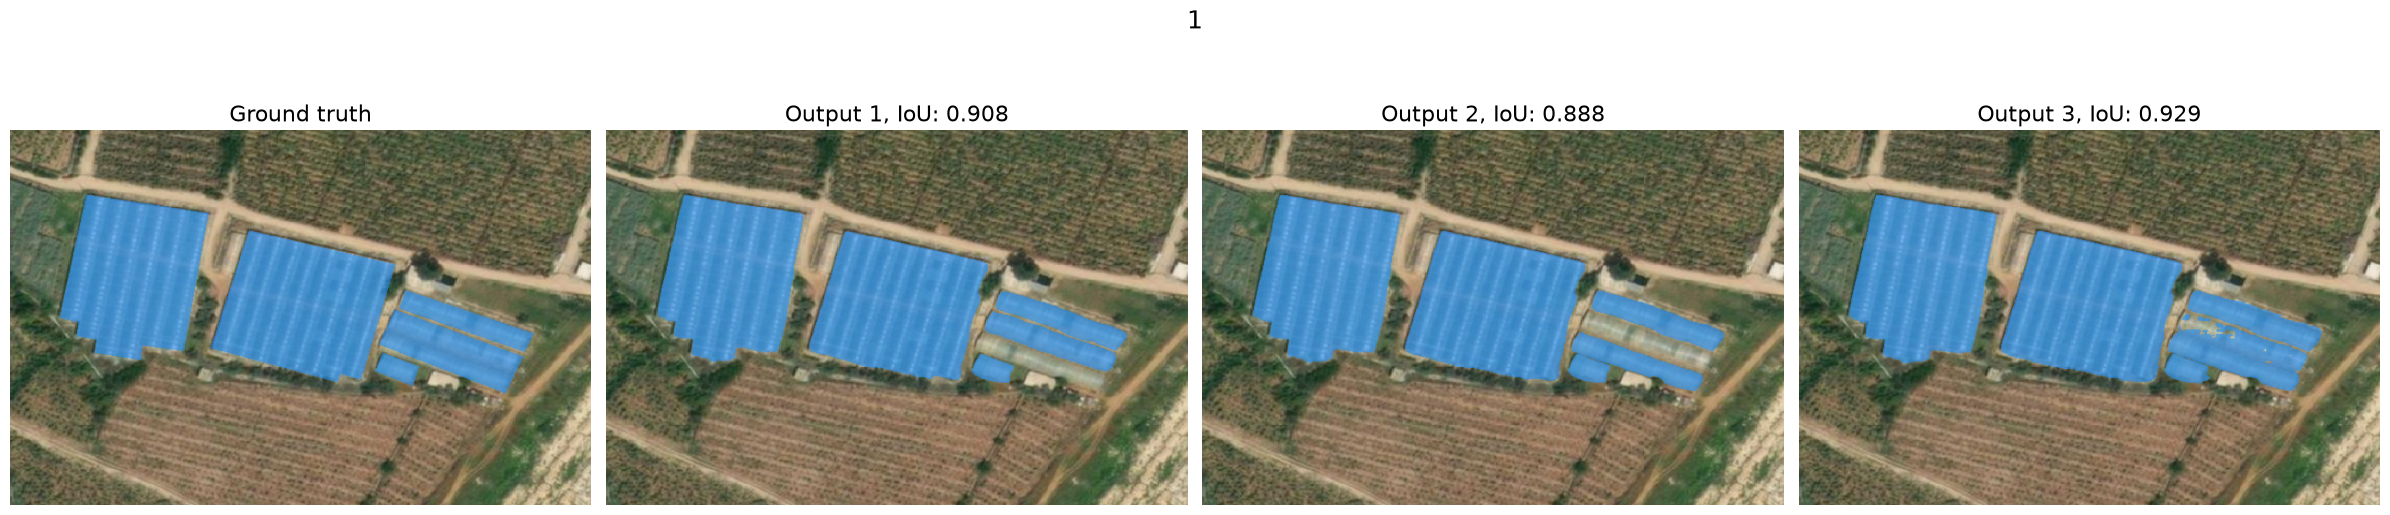

1it [00:01,  1.90s/it]

10 IoU per output slot: ['0.677', '0.912', '0.938']


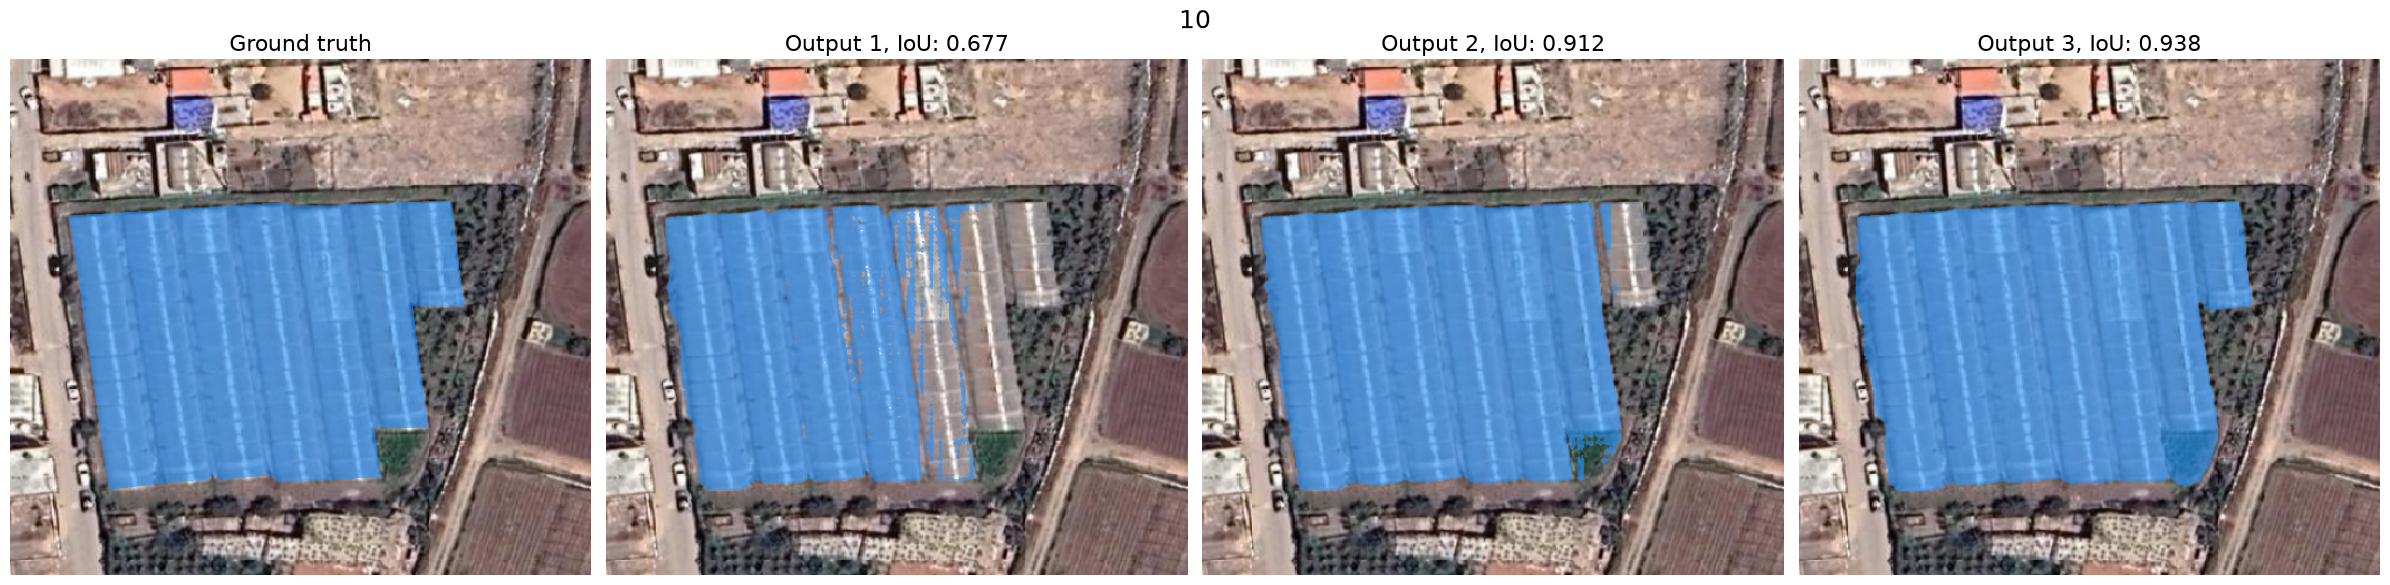

2it [00:03,  1.92s/it]

100 IoU per output slot: ['0.913', '0.918', '0.925']


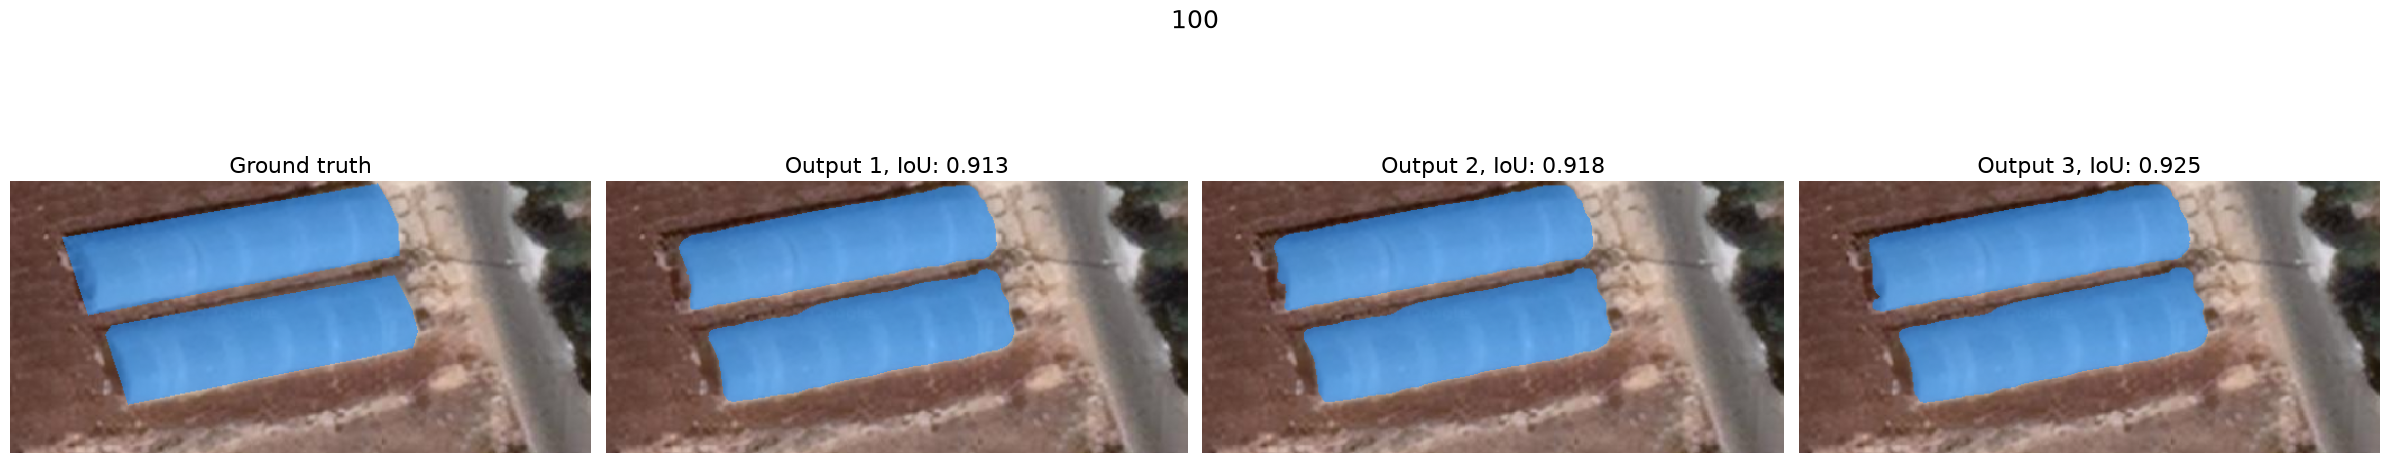

3it [00:05,  1.88s/it]


In [9]:
PROMPT = "box"   # "box", "interior", or "vertices"

images = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
masks = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'

for img_path, mask_path in tqdm(zip(glob(images+'/*.png')[:3], glob(masks+'/*.png'))):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    json_path = os.path.join(images, stem + '.json')
    image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 0
    with open(json_path) as fh:
        ann = json.load(fh)
    polygons = [np.array(s['points'], dtype=np.float32).reshape(-1, 2)
                for s in ann['shapes']]

    predictor.set_image(image)
    H, W = image.shape[:2]
    pred_tiles = np.zeros((3, H, W), dtype=bool)

    for poly in polygons:
        kwargs = {}
        kwargs["box"] = np.array([*poly.min(0), *poly.max(0)])
        # kwargs["point_coords"] = interior_point(poly, H, W)
        # kwargs["point_labels"] = np.array([1])
        # kwargs["point_coords"] = poly
        # kwargs["point_labels"] = np.ones(len(poly), dtype=np.int64)

        pred, scores, _ = predictor.predict(multimask_output=True, **kwargs)
        pred_tiles |= pred.astype(bool)

    ious = [iou(gt, t) for t in pred_tiles]
    print(stem, "IoU per output slot:", [f"{v:.3f}" for v in ious])

    # for k, (tile, v) in enumerate(zip(pred_tiles, ious)):
    #     plt.figure(figsize=(10, 10))
    #     plt.imshow(image)
    #     show_mask(tile, plt.gca())
    #     plt.title(f"Output {k+1}, IoU: {v:.3f}", fontsize=18)
    #     plt.axis('off')
    #     plt.show()


    fig, axes = plt.subplots(1, 4, figsize=(24, 6))

    # Ground truth
    axes[0].imshow(image)
    show_mask(gt, axes[0])
    axes[0].set_title("Ground truth", fontsize=16)
    axes[0].axis('off')

    # SAM outputs
    for k, (tile, v) in enumerate(zip(pred_tiles, ious)):
        ax = axes[k + 1]
        ax.imshow(image)
        show_mask(tile, ax)
        ax.set_title(f"Output {k+1}, IoU: {v:.3f}", fontsize=16)
        ax.axis('off')

    fig.suptitle(stem, fontsize=18)
    plt.tight_layout()
    plt.show()